In [9]:
import sys
# Trỏ chính xác đến thư mục chứa file data_utils.py của bạn
sys.path.append('/kaggle/input/datasets/alceanh19/models/HL')

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import matplotlib.pyplot as plt

# Import các module
from data_utils import load_fer2013_csv
from dataset import FER2013Dataset
from models import CustomCNN
from eval_utils import ten_crop_inference, generate_saliency_map, evaluate_private_test

# Truyền cả 2 đường dẫn (ảnh và nhãn FER+)
img_csv = "/kaggle/input/datasets/alceanh19/datasetfer/fer2013.csv"
label_csv = "/kaggle/input/datasets/alceanh19/fer-2013/fer2013new.csv"

# Khởi tạo dữ liệu (đã lọc bỏ ảnh rác NF và unknown)
(X_train, y_train), (X_val, y_val), (X_test, y_test) = load_fer2013_csv(img_csv, label_csv)

# Khởi tạo Dataset
train_dataset = FER2013Dataset(X_train, y_train, is_train=True)
val_dataset = FER2013Dataset(X_val, y_val, is_train=False)
test_dataset = FER2013Dataset(X_test, y_test, is_train=False)

# Khai báo batch_size chung
batch_size = 64

# Khởi tạo DataLoader
train_loader = DataLoader(
    train_dataset, 
    batch_size=batch_size, 
    shuffle=True, 
    drop_last=True
)

val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")

Đang ghép dữ liệu ảnh và nhãn FER+ (8 lớp) và lọc nhiễu...
Train: 26945, Val: 3234, Test: 3206


In [10]:
import torch.nn as nn
import torchvision.models as tv_models

def build_pretrained_resnet(num_classes=8):
    # Tải kiến trúc ResNet18 đã được huấn luyện trước
    model = tv_models.resnet18(weights=tv_models.ResNet18_Weights.DEFAULT)
    
    # Sửa lớp tích chập đầu tiên để nhận ảnh xám (1 kênh màu thay vì 3 kênh RGB)
    model.conv1 = nn.Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    
    # Sửa lớp phân loại cuối cùng để xuất ra đúng 8 lớp cảm xúc
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, num_classes)
    
    return model

print("Đã khởi tạo xong hàm build_pretrained_resnet!")

Đã khởi tạo xong hàm build_pretrained_resnet!


In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Đang huấn luyện trên thiết bị:", device)

#model = build_pretrained_resnet(num_classes=8).to(device)

model = CustomCNN(num_classes=8).to(device)

# 2. Hàm mất mát: Bỏ class_weight tuyến tính quá gắt và bật làm mịn nhãn label_smoothing=0.1
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

# 3. Thuật toán tối ưu (SGD + Nesterov Momentum)
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-4, nesterov=True)

# 4. Bộ giảm tốc độ học: Giảm 50% (factor=0.5) nếu Val_Acc không tăng sau 4 epoch (patience=4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=4)



Đang huấn luyện trên thiết bị: cuda


In [12]:
num_epochs = 75
best_val_acc = 0.0
patience = 15
patience_counter = 0

print("BẮT ĐẦU GIAI ĐOẠN 1: HUẤN LUYỆN CHÍNH...")
for epoch in range(num_epochs):
    # --- PHA TRAIN ---
    model.train()
    running_loss = 0.0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()               
        outputs = model(images)             
        loss = criterion(outputs, labels)   
        loss.backward()                     
        optimizer.step()                    
        
        running_loss += loss.item() * images.size(0)
        
    epoch_train_loss = running_loss / len(train_loader.dataset)
    
    # --- PHA VALIDATION ---
    model.eval()
    val_correct = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            preds = torch.argmax(outputs, dim=1)
            val_correct += (preds == labels).sum().item()
            
    epoch_val_acc = val_correct / len(val_loader.dataset)
    
    # Điều chỉnh tốc độ học dựa trên Val_Acc
    scheduler.step(epoch_val_acc)
    current_lr = optimizer.param_groups[0]['lr']
    
    print(f"Epoch [{epoch+1}/{num_epochs}] | LR: {current_lr:.6f} | Train Loss: {epoch_train_loss:.4f} | Val Acc: {epoch_val_acc*100:.2f}%")
    
    # --- LƯU FILE BEST & EARLY STOPPING ---
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save(model.state_dict(), 'best.pth')
        patience_counter = 0
        print("   -> (Kỷ lục mới) Đã lưu best.pth!")
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Dừng sớm (Early Stopping) tại Epoch {epoch+1}!")
            break

BẮT ĐẦU GIAI ĐOẠN 1: HUẤN LUYỆN CHÍNH...
Epoch [1/75] | LR: 0.010000 | Train Loss: 1.5541 | Val Acc: 66.05%
   -> (Kỷ lục mới) Đã lưu best.pth!
Epoch [2/75] | LR: 0.010000 | Train Loss: 1.3091 | Val Acc: 70.59%
   -> (Kỷ lục mới) Đã lưu best.pth!
Epoch [3/75] | LR: 0.010000 | Train Loss: 1.2177 | Val Acc: 72.63%
   -> (Kỷ lục mới) Đã lưu best.pth!
Epoch [4/75] | LR: 0.010000 | Train Loss: 1.1688 | Val Acc: 73.16%
   -> (Kỷ lục mới) Đã lưu best.pth!
Epoch [5/75] | LR: 0.010000 | Train Loss: 1.1370 | Val Acc: 75.17%
   -> (Kỷ lục mới) Đã lưu best.pth!
Epoch [6/75] | LR: 0.010000 | Train Loss: 1.1090 | Val Acc: 76.25%
   -> (Kỷ lục mới) Đã lưu best.pth!
Epoch [7/75] | LR: 0.010000 | Train Loss: 1.0842 | Val Acc: 76.81%
   -> (Kỷ lục mới) Đã lưu best.pth!
Epoch [8/75] | LR: 0.010000 | Train Loss: 1.0686 | Val Acc: 77.55%
   -> (Kỷ lục mới) Đã lưu best.pth!
Epoch [9/75] | LR: 0.010000 | Train Loss: 1.0496 | Val Acc: 78.88%
   -> (Kỷ lục mới) Đã lưu best.pth!
Epoch [10/75] | LR: 0.010000 | T

BẮT ĐẦU GIAI ĐOẠN 2: FINE-TUNING VỚI COSINE ANNEALING...
FT Epoch [1/20] | Val Acc: 83.49%
FT Epoch [2/20] | Val Acc: 83.36%
FT Epoch [3/20] | Val Acc: 83.09%
FT Epoch [4/20] | Val Acc: 83.15%
FT Epoch [5/20] | Val Acc: 83.09%
FT Epoch [6/20] | Val Acc: 83.27%
FT Epoch [7/20] | Val Acc: 83.02%
FT Epoch [8/20] | Val Acc: 83.12%
FT Epoch [9/20] | Val Acc: 83.24%
FT Epoch [10/20] | Val Acc: 83.12%
FT Epoch [11/20] | Val Acc: 83.30%
FT Epoch [12/20] | Val Acc: 83.24%
FT Epoch [13/20] | Val Acc: 83.18%
FT Epoch [14/20] | Val Acc: 83.09%
FT Epoch [15/20] | Val Acc: 83.30%
FT Epoch [16/20] | Val Acc: 83.55%
FT Epoch [17/20] | Val Acc: 83.30%
FT Epoch [18/20] | Val Acc: 83.21%
FT Epoch [19/20] | Val Acc: 83.58% -> Lưu best.pth mới!
FT Epoch [20/20] | Val Acc: 83.30%

--- HOÀN TẤT HUẤN LUYỆN ---

BẮT ĐẦU ĐÁNH GIÁ TRÊN TẬP TEST...
=== BÁO CÁO KIỂM ĐỊNH (CLASSIFICATION REPORT) ===
              precision    recall  f1-score   support

     Neutral     0.8274    0.8908    0.8579      1200
   Happi

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


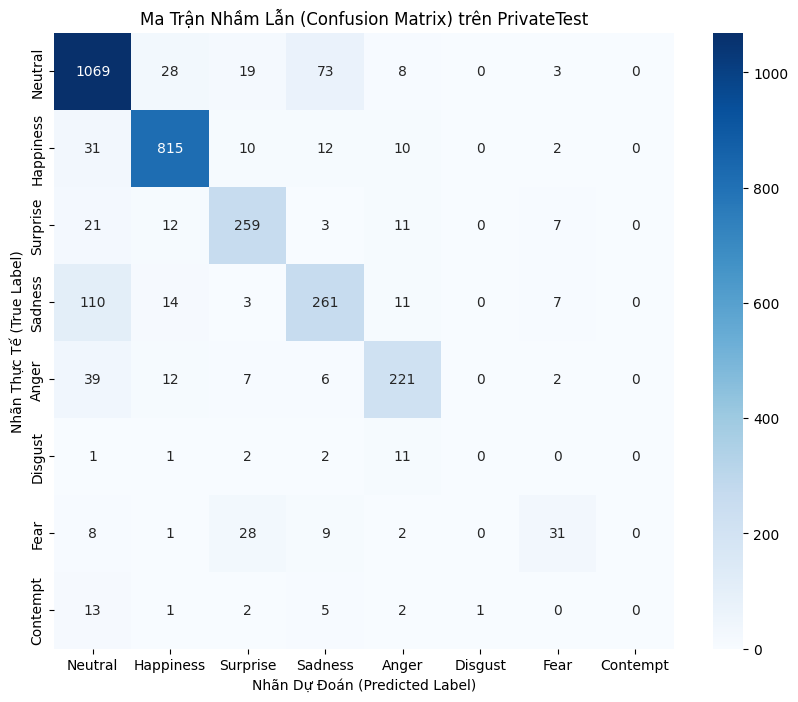

In [13]:
print("BẮT ĐẦU GIAI ĐOẠN 2: FINE-TUNING VỚI COSINE ANNEALING...")

if 'best_val_acc' not in globals():
    best_val_acc = 0.0

# 1. Nạp lại trọng số đỉnh cao nhất từ Giai đoạn 1
model.load_state_dict(torch.load('best.pth', weights_only=True))

# 2. Đặt tốc độ học khởi đầu là 5e-4 và dùng Cosine Annealing trong 20 epochs
ft_epochs = 20
optimizer_ft = optim.SGD(model.parameters(), lr=5e-4, momentum=0.9, weight_decay=1e-4, nesterov=True)
scheduler_ft = optim.lr_scheduler.CosineAnnealingLR(optimizer_ft, T_max=ft_epochs)

for epoch in range(ft_epochs):
    model.train()
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer_ft.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_ft.step()
        
    # Validation
    model.eval()
    val_correct = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            preds = torch.argmax(model(images), dim=1)
            val_correct += (preds == labels).sum().item()
            
    epoch_val_acc = val_correct / len(val_loader.dataset)
    scheduler_ft.step()
    
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save(model.state_dict(), 'best.pth')
        print(f"FT Epoch [{epoch+1}/{ft_epochs}] | Val Acc: {epoch_val_acc*100:.2f}% -> Lưu best.pth mới!")
    else:
        print(f"FT Epoch [{epoch+1}/{ft_epochs}] | Val Acc: {epoch_val_acc*100:.2f}%")

print("\n--- HOÀN TẤT HUẤN LUYỆN ---")

# Đánh giá tập Test
print("\nBẮT ĐẦU ĐÁNH GIÁ TRÊN TẬP TEST...")
model.load_state_dict(torch.load('best.pth', weights_only=True))
model.eval()

emotion_dict = {
    0: 'Neutral', 1: 'Happiness', 2: 'Surprise', 
    3: 'Sadness', 4: 'Anger', 5: 'Disgust', 
    6: 'Fear', 7: 'Contempt'
}

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)
        
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

evaluate_private_test(y_true, y_pred, emotion_dict)

BẮT ĐẦU GIAI ĐOẠN 3: KIỂM ĐỊNH TRÊN TẬP PRIVATETEST BẰNG TEN-CROP...
=== BÁO CÁO KIỂM ĐỊNH (CLASSIFICATION REPORT) ===
              precision    recall  f1-score   support

     Neutral     0.8188    0.8925    0.8541      1200
   Happiness     0.9236    0.9205    0.9220       880
    Surprise     0.7741    0.8211    0.7969       313
     Sadness     0.7139    0.6330    0.6710       406
       Anger     0.7849    0.7631    0.7739       287
     Disgust     0.0000    0.0000    0.0000        17
        Fear     0.6458    0.3924    0.4882        79
    Contempt     0.0000    0.0000    0.0000        24

    accuracy                         0.8250      3206
   macro avg     0.5826    0.5528    0.5633      3206
weighted avg     0.8122    0.8250    0.8168      3206



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


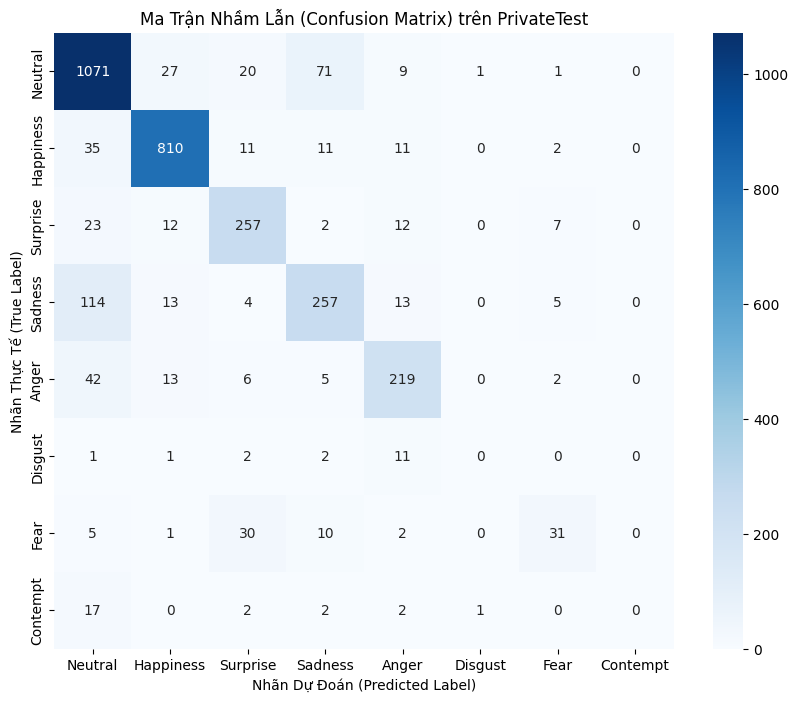

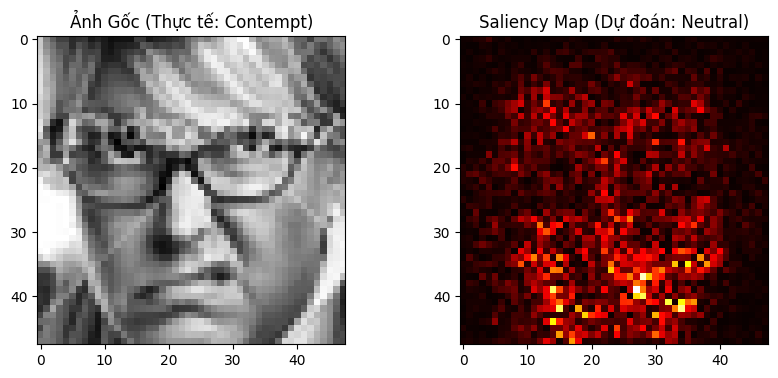

In [14]:
print("BẮT ĐẦU GIAI ĐOẠN 3: KIỂM ĐỊNH TRÊN TẬP PRIVATETEST BẰNG TEN-CROP...")

# 1. Nạp file trọng số cuối cùng (Sửa thành 'best_model_custom.pth' nếu bạn đã đổi tên file ở bước trước)
model.load_state_dict(torch.load('best.pth', weights_only=True))
model.eval()

y_true = []
y_pred = []

# 2. Chạy Ten-Crop Averaging (Lưu ý: Mất nhiều thời gian hơn một chút vì 1 ảnh thành 10 ảnh)
for images, labels in test_loader:
    for i in range(images.size(0)):
        img_tensor = images[i]
        true_label = labels[i].item()
        
        # Gọi hàm từ eval_utils.py
        pred_label, _ = ten_crop_inference(model, img_tensor)
        
        y_true.append(true_label)
        y_pred.append(pred_label)

# 3. Xuất Báo cáo và Ma trận nhầm lẫn (Đã cập nhật chuẩn 8 lớp của FER+)
emotion_dict = {
    0: 'Neutral', 
    1: 'Happiness', 
    2: 'Surprise', 
    3: 'Sadness', 
    4: 'Anger', 
    5: 'Disgust', 
    6: 'Fear', 
    7: 'Contempt'
}
evaluate_private_test(y_true, y_pred, emotion_dict)

# 4. Trực quan hóa Saliency Map cho 1 ảnh Test bất kỳ
sample_img = test_dataset[0][0] # Lấy ảnh đầu tiên của tập Test
sample_label = test_dataset[0][1].item()

saliency, pred_class = generate_saliency_map(model, sample_img)

# Vẽ đồ thị Saliency
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(sample_img.squeeze().numpy(), cmap='gray')
plt.title(f"Ảnh Gốc (Thực tế: {emotion_dict[sample_label]})")

plt.subplot(1, 2, 2)
plt.imshow(saliency, cmap='hot')
plt.title(f"Saliency Map (Dự đoán: {emotion_dict[pred_class]})")
plt.show()